<a href="https://colab.research.google.com/github/Bnas69/Bnas69.github.io/blob/main/411232056_septian_dwi_saputra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Membuat basis data dan mengisi data

In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Basis data sementara di memori Colab
conn = sqlite3.connect(":memory:")
conn.execute("PRAGMA foreign_keys = ON")

conn.executescript("""
CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")

# 5 buku
conn.executemany(
    "INSERT INTO buku (id, judul, penulis, tahun) VALUES (?, ?, ?, ?)",
    [
        (1, "Laskar Pelangi", "Andrea Hirata", 2005),
        (2, "Bumi Manusia", "Pramoedya Ananta Toer", 1980),
        (3, "Atomic Habits", "James Clear", 2018),
        (4, "Filosofi Teras", "Henry Manampiring", 2018),
        (5, "Laut Bercerita", "Leila S. Chudori", 2017),
    ],
)

# 3 anggota
conn.executemany(
    "INSERT INTO anggota (id, nama, email) VALUES (?, ?, ?)",
    [
        (1, "Aisyah", "aisyah@example.com"),
        (2, "Budi", "budi@example.com"),
        (3, "Citra", "citra@example.com"),
    ],
)

# 4 transaksi; transaksi ketiga belum dikembalikan
conn.executemany(
    """
    INSERT INTO peminjaman
        (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
    VALUES (?, ?, ?, ?, ?)
    """,
    [
        (1, 1, 1, "2026-10-01", "2026-10-08"),
        (2, 1, 3, "2026-10-05", "2026-10-12"),
        (3, 2, 2, "2026-10-10", None),
        (4, 3, 4, "2026-10-15", "2026-10-20"),
    ],
)

conn.commit()
print("Basis data dan data contoh berhasil dibuat.")

Basis data dan data contoh berhasil dibuat.


1c. Menampilkan daftar peminjaman dengan JOIN


In [4]:
query_peminjaman = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_peminjaman, conn)
display(df_peminjaman)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Aisyah,Laskar Pelangi,2026-10-01,2026-10-08
1,2,Aisyah,Atomic Habits,2026-10-05,2026-10-12
2,3,Budi,Bumi Manusia,2026-10-10,None
3,4,Citra,Filosofi Teras,2026-10-15,2026-10-20


1d. Menghitung jumlah buku yang dipinjam per anggota
LEFT JOIN memastikan anggota yang belum memiliki peminjaman tetap tampil.

In [5]:
query_jumlah_per_anggota = """
SELECT
    a.nama,
    COUNT(p.id) AS jumlah_buku_dipinjam
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY a.id;
"""

df_anggota = pd.read_sql_query(query_jumlah_per_anggota, conn)
display(df_anggota)

,nama,jumlah_buku_dipinjam
0,Aisyah,2
1,Budi,1
2,Citra,1


2. Eksplorasi data dan visualisasi

In [6]:
df_peminjaman["tgl_pinjam"] = pd.to_datetime(df_peminjaman["tgl_pinjam"])
df_peminjaman["tgl_kembali"] = pd.to_datetime(
    df_peminjaman["tgl_kembali"], errors="coerce"
)

df_peminjaman["durasi_hari"] = (
    df_peminjaman["tgl_kembali"] - df_peminjaman["tgl_pinjam"]
).dt.days

display(df_peminjaman)

print("Ringkasan durasi peminjaman yang sudah dikembalikan:")
display(df_peminjaman["durasi_hari"].dropna().describe())

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari
0,1,Aisyah,Laskar Pelangi,2026-10-01,2026-10-08,7.0
1,2,Aisyah,Atomic Habits,2026-10-05,2026-10-12,7.0
2,3,Budi,Bumi Manusia,2026-10-10,NaT,NaN
3,4,Citra,Filosofi Teras,2026-10-15,2026-10-20,5.0


Ringkasan durasi peminjaman yang sudah dikembalikan:


,durasi_hari
count,3.000000
mean,6.333333
std,1.154701
min,5.000000
25%,6.000000
50%,7.000000
75%,7.000000
max,7.000000


histogram durasi peminjaman dan diagram batang jumlah buku per anggota:

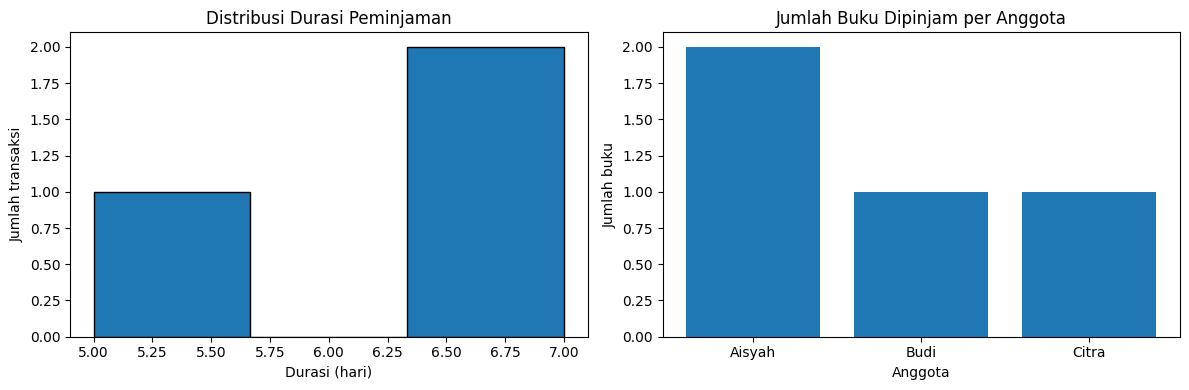

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

durasi_selesai = df_peminjaman["durasi_hari"].dropna()
axes[0].hist(durasi_selesai, bins="auto", edgecolor="black")
axes[0].set_title("Distribusi Durasi Peminjaman")
axes[0].set_xlabel("Durasi (hari)")
axes[0].set_ylabel("Jumlah transaksi")

axes[1].bar(df_anggota["nama"], df_anggota["jumlah_buku_dipinjam"])
axes[1].set_title("Jumlah Buku Dipinjam per Anggota")
axes[1].set_xlabel("Anggota")
axes[1].set_ylabel("Jumlah buku")

plt.tight_layout()
plt.show()